In [4]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import cv2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/simuteh-1004"

DATA = os.path.join(BASE, "data", "sintetis")
CITRA = os.path.join(DATA, "citra")
BERSIH = os.path.join(DATA, "bersih")
MASK_DAUN = os.path.join(DATA, "mask_daun")
MASK_BERCAK = os.path.join(DATA, "mask_bercak")

SRC = os.path.join(BASE, "src")
HASIL = os.path.join(BASE, "hasil")

os.makedirs(HASIL, exist_ok=True)

if SRC not in sys.path:
    sys.path.insert(0, SRC)

from praproses import praproses, simpan_param
from utils_cv import baca, kontras_bercak

print("Persiapan B5 selesai.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Persiapan B5 selesai.


In [5]:
PARAM_FINAL = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0
}

print("Parameter praproses:")
for nama, nilai in PARAM_FINAL.items():
    print(f"{nama}: {nilai}")

Parameter praproses:
lebar: 640
gamma: 1.0
clahe_clip: 2.0
clahe_tile: 8
penapis: median
kernel: 3
sigma: 1.0
tajam_k: 0.0


In [6]:
path_json = os.path.join(
    HASIL,
    "param_praproses.json"
)

simpan_param(PARAM_FINAL, path_json)

print("Parameter berhasil disimpan:")
print(path_json)

with open(path_json, "r") as f:
    print(f.read())

Parameter berhasil disimpan:
/content/drive/MyDrive/simuteh-1004/hasil/param_praproses.json
{
  "lebar": 640,
  "gamma": 1.0,
  "clahe_clip": 2.0,
  "clahe_tile": 8,
  "penapis": "median",
  "kernel": 3,
  "sigma": 1.0,
  "tajam_k": 0.0
}


In [7]:
KANAL = 2

nama_kanal = {
    0: "Biru",
    1: "Hijau",
    2: "Merah"
}

print("Kanal evaluasi:", nama_kanal[KANAL])

Kanal evaluasi: Merah


In [8]:
path_label = os.path.join(DATA, "label.csv")

label = pd.read_csv(path_label)

print("Kolom label:")
print(label.columns.tolist())

display(label.head())

print("\nJumlah kelas:")
print(label["kelas"].value_counts())

print("\nKondisi pencahayaan:")
print(label["kondisi_cahaya"].value_counts())

Kolom label:
['nama_file', 'kelas', 'kondisi_cahaya', 'persen_bercak']


,nama_file,kelas,kondisi_cahaya,persen_bercak
0,teh_001.png,sehat,normal,0.0
1,teh_002.png,sehat,gelap,0.0
2,teh_003.png,sehat,terang,0.0
3,teh_004.png,sehat,kontras_rendah,0.0
4,teh_005.png,sehat,bayangan,0.0



Jumlah kelas:
kelas
sehat     20
ringan    20
berat     20
Name: count, dtype: int64

Kondisi pencahayaan:
kondisi_cahaya
normal            12
gelap             12
terang            12
kontras_rendah    12
bayangan          12
Name: count, dtype: int64


In [9]:
def baca_mask(path):
    mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if mask is None:
        raise FileNotFoundError(path)

    return mask


def sesuaikan_mask(mask, bentuk):
    tinggi, lebar = bentuk[:2]

    return cv2.resize(
        mask,
        (lebar, tinggi),
        interpolation=cv2.INTER_NEAREST
    )


def hitung_std_daun(citra, mask_daun, kanal):
    mask = sesuaikan_mask(mask_daun, citra.shape)

    area_daun = mask > 0

    nilai = citra[:, :, kanal][area_daun]

    if len(nilai) == 0:
        return np.nan

    return float(np.std(nilai))


def hitung_kb_ukuran_sesuai(citra, mask_daun, mask_bercak, kanal):
    md = sesuaikan_mask(mask_daun, citra.shape)
    mb = sesuaikan_mask(mask_bercak, citra.shape)

    return kontras_bercak(
        citra[:, :, kanal],
        md,
        mb
    )


print("Fungsi evaluasi berhasil dibuat.")

Fungsi evaluasi berhasil dibuat.


In [10]:
baris = []

data_berbercak = label[
    label["kelas"].str.lower() != "sehat"
].copy()

for _, d in data_berbercak.iterrows():

    nama = d["nama_file"]

    path = os.path.join(CITRA, nama)
    path_md = os.path.join(MASK_DAUN, nama)
    path_mb = os.path.join(MASK_BERCAK, nama)

    img = baca(path)

    if img is None:
        raise FileNotFoundError(path)

    md = baca_mask(path_md)
    mb = baca_mask(path_mb)

    out = praproses(img, PARAM_FINAL)

    kb_sebelum = hitung_kb_ukuran_sesuai(
        img, md, mb, KANAL
    )

    kb_sesudah = hitung_kb_ukuran_sesuai(
        out, md, mb, KANAL
    )

    baris.append({
        "nama_file": nama,
        "kondisi": d["kondisi_cahaya"],
        "KB_sebelum": kb_sebelum,
        "KB_sesudah": kb_sesudah
    })

evaluasi = pd.DataFrame(baris)

print("Jumlah citra berbercak:", len(evaluasi))

display(evaluasi.head())

Jumlah citra berbercak: 40


,nama_file,kondisi,KB_sebelum,KB_sesudah
0,teh_021.png,normal,7.290657,9.194757
1,teh_022.png,gelap,6.613089,12.619838
2,teh_023.png,terang,8.645563,7.968295
3,teh_024.png,kontras_rendah,2.316455,3.513899
4,teh_025.png,bayangan,4.211578,7.286401


In [11]:
tabel_12 = (
    evaluasi
    .groupby("kondisi")
    .agg(
        KB_sebelum=("KB_sebelum", "mean"),
        KB_sesudah=("KB_sesudah", "mean")
    )
    .reset_index()
)

tabel_12["Perubahan (%)"] = np.where(
    tabel_12["KB_sebelum"] != 0,
    (
        (tabel_12["KB_sesudah"] - tabel_12["KB_sebelum"])
        / tabel_12["KB_sebelum"]
    ) * 100,
    np.nan
)

tabel_12 = tabel_12.rename(
    columns={"kondisi": "Kondisi"}
)

print("TABEL 12. EVALUASI RANGKAIAN PRAPROSES")

display(tabel_12.round(3))

tabel_12.to_csv(
    os.path.join(HASIL, "b5_tabel_12.csv"),
    index=False
)

evaluasi.to_csv(
    os.path.join(HASIL, "b5_evaluasi_40_citra.csv"),
    index=False
)

TABEL 12. EVALUASI RANGKAIAN PRAPROSES


,Kondisi,KB_sebelum,KB_sesudah,Perubahan (%)
0,bayangan,5.004,8.150,62.876
1,gelap,11.007,18.623,69.202
2,kontras_rendah,3.685,4.914,33.343
3,normal,9.112,11.642,27.760
4,terang,6.303,6.155,-2.346


In [12]:
data_sehat = label[
    label["kelas"].str.lower() == "sehat"
].copy()

data_sehat = data_sehat.sort_values("nama_file")

print("Jumlah citra kelas sehat:", len(data_sehat))

display(data_sehat[["nama_file", "kelas", "kondisi_cahaya"]])

Jumlah citra kelas sehat: 20


,nama_file,kelas,kondisi_cahaya
0,teh_001.png,sehat,normal
1,teh_002.png,sehat,gelap
2,teh_003.png,sehat,terang
3,teh_004.png,sehat,kontras_rendah
4,teh_005.png,sehat,bayangan
5,teh_006.png,sehat,normal
6,teh_007.png,sehat,gelap
7,teh_008.png,sehat,terang
8,teh_009.png,sehat,kontras_rendah
9,teh_010.png,sehat,bayangan


In [13]:
hasil_sehat = []

for _, d in data_sehat.iterrows():

    nama = d["nama_file"]

    path = os.path.join(CITRA, nama)
    path_md = os.path.join(MASK_DAUN, nama)

    img = baca(path)

    if img is None:
        raise FileNotFoundError(path)

    md = baca_mask(path_md)

    out = praproses(img, PARAM_FINAL)

    std_sebelum = hitung_std_daun(
        img,
        md,
        KANAL
    )

    std_sesudah = hitung_std_daun(
        out,
        md,
        KANAL
    )

    hasil_sehat.append({
        "nama_file": nama,
        "kondisi": d["kondisi_cahaya"],
        "STD_sebelum": std_sebelum,
        "STD_sesudah": std_sesudah
    })

df_sehat = pd.DataFrame(hasil_sehat)

print("Hasil pengujian kelas sehat:")
display(df_sehat.round(3))

Hasil pengujian kelas sehat:


,nama_file,kondisi,STD_sebelum,STD_sesudah
0,teh_001.png,normal,14.521,10.608
1,teh_002.png,gelap,9.127,5.717
2,teh_003.png,terang,9.138,11.736
3,teh_004.png,kontras_rendah,13.086,10.878
4,teh_005.png,bayangan,13.175,10.431
5,teh_006.png,normal,12.178,10.516
6,teh_007.png,gelap,8.006,6.033
7,teh_008.png,terang,7.987,10.795
8,teh_009.png,kontras_rendah,13.509,11.833
9,teh_010.png,bayangan,12.301,11.091


In [14]:
tabel_sehat = (
    df_sehat
    .groupby("kondisi")
    .agg(
        STD_sebelum=("STD_sebelum", "mean"),
        STD_sesudah=("STD_sesudah", "mean")
    )
    .reset_index()
)

tabel_sehat["Perubahan (%)"] = np.where(
    tabel_sehat["STD_sebelum"] != 0,
    (
        (tabel_sehat["STD_sesudah"] - tabel_sehat["STD_sebelum"])
        / tabel_sehat["STD_sebelum"]
    ) * 100,
    np.nan
)

tabel_sehat = tabel_sehat.rename(
    columns={"kondisi": "Kondisi"}
)

print("HASIL UJI BERCAK PALSU PADA KELAS SEHAT")

display(tabel_sehat.round(3))

tabel_sehat.to_csv(
    os.path.join(HASIL, "b5_uji_bercak_palsu.csv"),
    index=False
)

df_sehat.to_csv(
    os.path.join(HASIL, "b5_detail_20_citra_sehat.csv"),
    index=False
)

HASIL UJI BERCAK PALSU PADA KELAS SEHAT


,Kondisi,STD_sebelum,STD_sesudah,Perubahan (%)
0,bayangan,12.866,10.238,-20.427
1,gelap,8.182,5.704,-30.281
2,kontras_rendah,12.853,11.471,-10.757
3,normal,11.926,9.725,-18.455
4,terang,9.972,11.510,15.423


In [15]:
kondisi_unik = data_sehat["kondisi_cahaya"].dropna().unique()

fig, axes = plt.subplots(
    len(kondisi_unik),
    2,
    figsize=(12, 4 * len(kondisi_unik))
)

if len(kondisi_unik) == 1:
    axes = np.array([axes])

for i, kondisi in enumerate(kondisi_unik):

    baris_kondisi = data_sehat[
        data_sehat["kondisi_cahaya"] == kondisi
    ].iloc[0]

    nama = baris_kondisi["nama_file"]

    img = baca(os.path.join(CITRA, nama))
    out = praproses(img, PARAM_FINAL)

    axes[i, 0].imshow(
        cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    )
    axes[i, 0].set_title(
        f"{kondisi} - Sebelum ({nama})"
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(
        cv2.cvtColor(out, cv2.COLOR_BGR2RGB)
    )
    axes[i, 1].set_title(
        f"{kondisi} - Sesudah ({nama})"
    )
    axes[i, 1].axis("off")

plt.suptitle(
    "Perbandingan Citra Kelas Sehat Sebelum dan Sesudah Praproses",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    os.path.join(HASIL, "b5_panel_bercak_palsu.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Output hidden; open in https://colab.research.google.com to view.

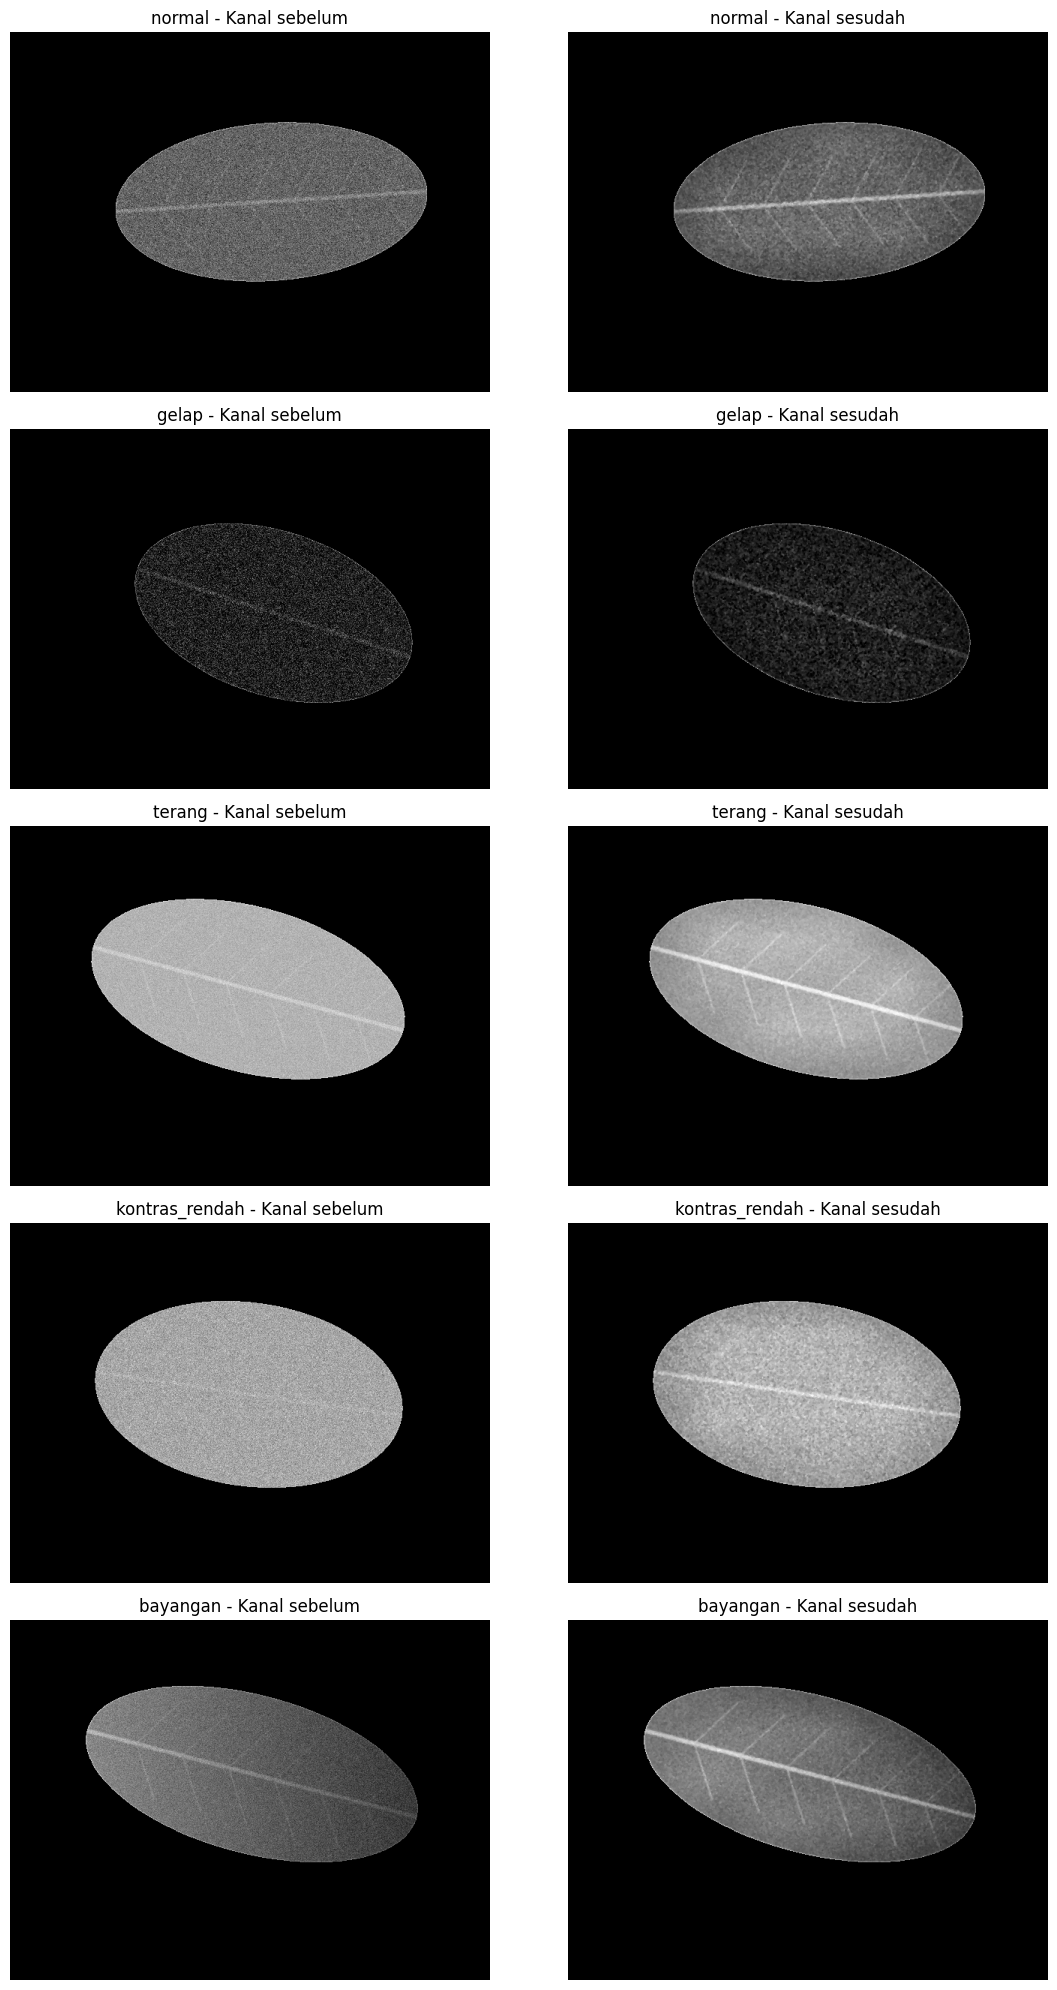

In [16]:
fig, axes = plt.subplots(
    len(kondisi_unik),
    2,
    figsize=(12, 4 * len(kondisi_unik))
)

if len(kondisi_unik) == 1:
    axes = np.array([axes])

for i, kondisi in enumerate(kondisi_unik):

    baris_kondisi = data_sehat[
        data_sehat["kondisi_cahaya"] == kondisi
    ].iloc[0]

    nama = baris_kondisi["nama_file"]

    img = baca(os.path.join(CITRA, nama))
    md = baca_mask(os.path.join(MASK_DAUN, nama))

    out = praproses(img, PARAM_FINAL)

    md_sebelum = sesuaikan_mask(md, img.shape)
    md_sesudah = sesuaikan_mask(md, out.shape)

    kanal_sebelum = img[:, :, KANAL].copy()
    kanal_sesudah = out[:, :, KANAL].copy()

    kanal_sebelum[md_sebelum == 0] = 0
    kanal_sesudah[md_sesudah == 0] = 0

    axes[i, 0].imshow(kanal_sebelum, cmap="gray")
    axes[i, 0].set_title(f"{kondisi} - Kanal sebelum")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(kanal_sesudah, cmap="gray")
    axes[i, 1].set_title(f"{kondisi} - Kanal sesudah")
    axes[i, 1].axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(HASIL, "b5_panel_kanal_sehat.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
tabel_13 = pd.DataFrame([
    {
        "Langkah": "1. Ubah ukuran",
        "Parameter final": f"Lebar {PARAM_FINAL['lebar']} piksel",
        "Alasan dan bukti": "Menyesuaikan ukuran citra kerja dan menjaga rasio aspek.",
        "Risiko bila salah atur": "Detail citra dapat hilang atau ukuran citra tidak seragam."
    },
    {
        "Langkah": "2. Koreksi gamma",
        "Parameter final": PARAM_FINAL["gamma"],
        "Alasan dan bukti": "Ditentukan berdasarkan hasil evaluasi pencahayaan pada B3.",
        "Risiko bila salah atur": "Citra dapat terlalu terang atau terlalu gelap."
    },
    {
        "Langkah": "3. CLAHE kanal V",
        "Parameter final": f"Clip {PARAM_FINAL['clahe_clip']}, tile {PARAM_FINAL['clahe_tile']}",
        "Alasan dan bukti": "Ditentukan berdasarkan perbandingan peningkatan kontras pada B3.",
        "Risiko bila salah atur": "Kontras berlebihan dapat memperkuat derau."
    },
    {
        "Langkah": "4. Redam derau",
        "Parameter final": f"{PARAM_FINAL['penapis']}, kernel {PARAM_FINAL['kernel']}",
        "Alasan dan bukti": "Ditentukan berdasarkan PSNR, waktu, dan KB pada B4.",
        "Risiko bila salah atur": "Bercak kecil dapat menjadi kabur atau hilang."
    },
    {
        "Langkah": "5. Tajamkan",
        "Parameter final": PARAM_FINAL["tajam_k"],
        "Alasan dan bukti": "Ditentukan berdasarkan pengamatan ketajaman dan perubahan derau.",
        "Risiko bila salah atur": "Penajaman berlebihan dapat menghasilkan artefak."
    }
])

print("TABEL 13. JUSTIFIKASI RANGKAIAN PRAPROSES")

display(tabel_13)

tabel_13.to_csv(
    os.path.join(HASIL, "b5_tabel_13.csv"),
    index=False
)

TABEL 13. JUSTIFIKASI RANGKAIAN PRAPROSES


,Langkah,Parameter final,Alasan dan bukti,Risiko bila salah atur
0,1. Ubah ukuran,Lebar 640 piksel,Menyesuaikan ukuran citra kerja dan menjaga ra...,Detail citra dapat hilang atau ukuran citra ti...
1,2. Koreksi gamma,1.0,Ditentukan berdasarkan hasil evaluasi pencahay...,Citra dapat terlalu terang atau terlalu gelap.
2,3. CLAHE kanal V,"Clip 2.0, tile 8",Ditentukan berdasarkan perbandingan peningkata...,Kontras berlebihan dapat memperkuat derau.
3,4. Redam derau,"median, kernel 3","Ditentukan berdasarkan PSNR, waktu, dan KB pad...",Bercak kecil dapat menjadi kabur atau hilang.
4,5. Tajamkan,0.0,Ditentukan berdasarkan pengamatan ketajaman da...,Penajaman berlebihan dapat menghasilkan artefak.


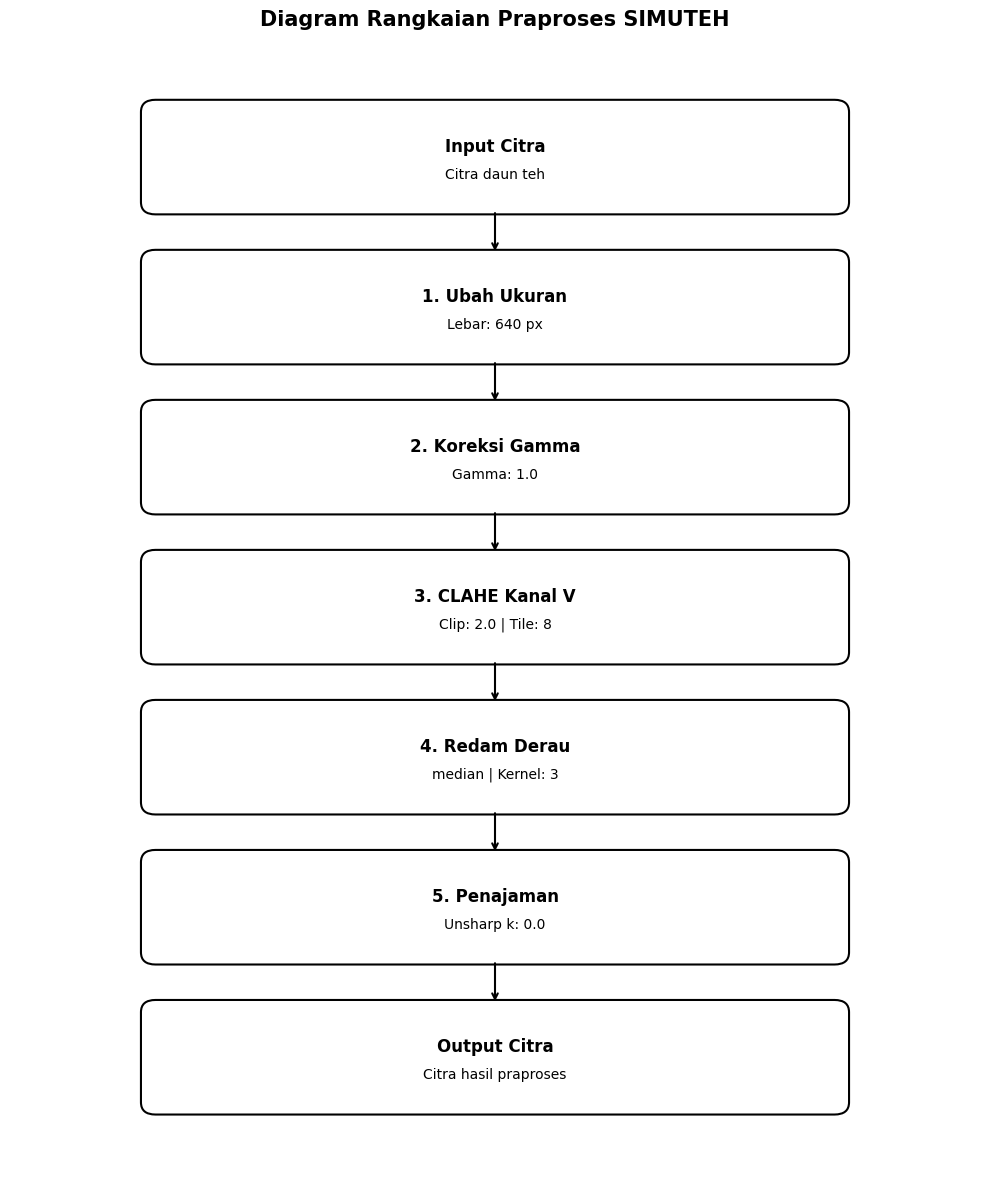

In [18]:
from matplotlib.patches import FancyBboxPatch

langkah = [
    ("Input Citra", "Citra daun teh"),
    ("1. Ubah Ukuran", f"Lebar: {PARAM_FINAL['lebar']} px"),
    ("2. Koreksi Gamma", f"Gamma: {PARAM_FINAL['gamma']}"),
    ("3. CLAHE Kanal V", f"Clip: {PARAM_FINAL['clahe_clip']} | Tile: {PARAM_FINAL['clahe_tile']}"),
    ("4. Redam Derau", f"{PARAM_FINAL['penapis']} | Kernel: {PARAM_FINAL['kernel']}"),
    ("5. Penajaman", f"Unsharp k: {PARAM_FINAL['tajam_k']}"),
    ("Output Citra", "Citra hasil praproses")
]

fig, ax = plt.subplots(figsize=(10, 12))

ax.set_xlim(0, 10)
ax.set_ylim(0, 14)
ax.axis("off")

posisi_y = np.linspace(12.5, 1.5, len(langkah))

for i, (judul, keterangan) in enumerate(langkah):

    y = posisi_y[i]

    kotak = FancyBboxPatch(
        (1.5, y - 0.55),
        7,
        1.1,
        boxstyle="round,pad=0.15",
        linewidth=1.5,
        edgecolor="black",
        facecolor="white"
    )

    ax.add_patch(kotak)

    ax.text(
        5,
        y + 0.12,
        judul,
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold"
    )

    ax.text(
        5,
        y - 0.22,
        keterangan,
        ha="center",
        va="center",
        fontsize=10
    )

    if i < len(langkah) - 1:
        ax.annotate(
            "",
            xy=(5, posisi_y[i + 1] + 0.65),
            xytext=(5, y - 0.65),
            arrowprops=dict(arrowstyle="->", linewidth=1.5)
        )

plt.title(
    "Diagram Rangkaian Praproses SIMUTEH",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(HASIL, "b5_diagram_praproses.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
print("=== RANGKUMAN HASIL B5 ===")

print("\nJumlah citra berbercak:", len(evaluasi))
print("Jumlah citra sehat:", len(df_sehat))

print("\nTabel 12:")
display(tabel_12.round(3))

print("\nHasil uji bercak palsu:")
display(tabel_sehat.round(3))

print("\nTabel 13:")
display(tabel_13)

print("\nFile hasil B5:")

for file in sorted(os.listdir(HASIL)):
    if file.startswith("b5_") or file == "param_praproses.json":
        print("-", file)

=== RANGKUMAN HASIL B5 ===

Jumlah citra berbercak: 40
Jumlah citra sehat: 20

Tabel 12:


,Kondisi,KB_sebelum,KB_sesudah,Perubahan (%)
0,bayangan,5.004,8.150,62.876
1,gelap,11.007,18.623,69.202
2,kontras_rendah,3.685,4.914,33.343
3,normal,9.112,11.642,27.760
4,terang,6.303,6.155,-2.346



Hasil uji bercak palsu:


,Kondisi,STD_sebelum,STD_sesudah,Perubahan (%)
0,bayangan,12.866,10.238,-20.427
1,gelap,8.182,5.704,-30.281
2,kontras_rendah,12.853,11.471,-10.757
3,normal,11.926,9.725,-18.455
4,terang,9.972,11.510,15.423



Tabel 13:


,Langkah,Parameter final,Alasan dan bukti,Risiko bila salah atur
0,1. Ubah ukuran,Lebar 640 piksel,Menyesuaikan ukuran citra kerja dan menjaga ra...,Detail citra dapat hilang atau ukuran citra ti...
1,2. Koreksi gamma,1.0,Ditentukan berdasarkan hasil evaluasi pencahay...,Citra dapat terlalu terang atau terlalu gelap.
2,3. CLAHE kanal V,"Clip 2.0, tile 8",Ditentukan berdasarkan perbandingan peningkata...,Kontras berlebihan dapat memperkuat derau.
3,4. Redam derau,"median, kernel 3","Ditentukan berdasarkan PSNR, waktu, dan KB pad...",Bercak kecil dapat menjadi kabur atau hilang.
4,5. Tajamkan,0.0,Ditentukan berdasarkan pengamatan ketajaman da...,Penajaman berlebihan dapat menghasilkan artefak.



File hasil B5:
- b5_detail_20_citra_sehat.csv
- b5_diagram_praproses.png
- b5_evaluasi_40_citra.csv
- b5_panel_bercak_palsu.png
- b5_panel_kanal_sehat.png
- b5_ringkasan_citra_sehat.csv
- b5_tabel_12.csv
- b5_tabel_13.csv
- b5_uji_bercak_palsu.csv
- b5_uji_citra_sehat.csv
- param_praproses.json
